# Isaac Joffe, 2026

In [1]:
from utils import *
from nns import *
from search import *

metadata = {}
results = {}


Torch device: cpu


In [2]:
DEEPCODER_HYPERPARAMS = {
    "input_dim": int(2 * GRID_REPRESENTATION_DIMENSIONS),
    "hidden_dim": 128,
    "output_dim": N_PRIMITIVES,
    "n_hidden_layers": 2,
    "hidden_layer_sizes": "log",
    "n_epochs": 1000,
    "early_stopping": True,
    "stopping_window": 10,
    "batch_size": 256,
    "learning_rate": 0.0001,
    "regularization_factor": 1,
    "dropout_factor": 0.5,
    "label_smoothing_factor": 0.01,
}


### Simple Baseline: Naive Enumeration

In [3]:
metadata["Naive Baseline"] = [{}]


In [4]:
results = try_all_tasks(metadata, results)



Now using: Naive Baseline

Now solving 1cf80156...


0it [00:00, ?it/s]


Program found: `ColourHypothesis; Crop(x)()` correctly solved all demonstrations (1th attempt)
Correct: Found solution program 1 correctly solved all queries.

Now solving 28bf18c6...


1676it [00:00, 5060.30it/s]


Program found: `ColourHypothesis; HStack(Crop(x)(), Crop(x)())()` correctly solved all demonstrations (1677th attempt)
Correct: Found solution program 1 correctly solved all queries.

Now solving 3c9b0459...


8it [00:00, 4366.79it/s]


... (108 outputs left out)

1343it [00:00, 4022.97it/s]


Program found: `ColourHypothesis; ArgMax(Crop(x)(), ObjectGetPixelCount(x)())()` correctly solved all demonstrations (1344th attempt)
Correct: Found solution program 1 correctly solved all queries.

Now solving be94b721...


1343it [00:00, 5170.83it/s]

Program found: `ColourHypothesis; ArgMax(Crop(x)(), ObjectGetPixelCount(x)())()` correctly solved all demonstrations (1344th attempt)
Correct: Found solution program 1 correctly solved all queries.


Scores (Average Area Under the Curve):
	Naive Baseline: 0.359



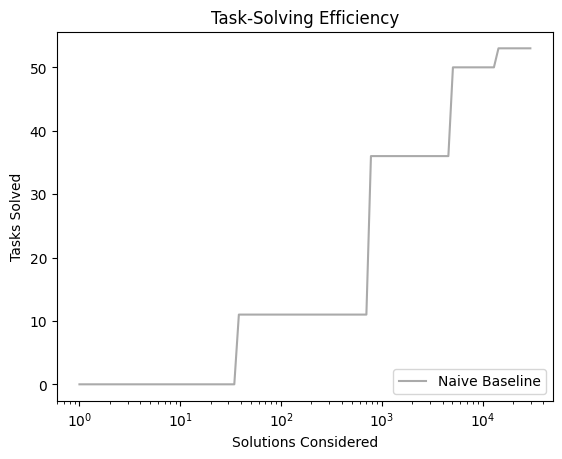

In [5]:
scores = plot_task_solving_efficiency(results)


### Complex Baseline: DeepCoder Approach

In [6]:
# DeepCoder enumeration with 1 NN

for p1 in ["Naive", "1", "2", "3", "All"]:

    label = f"DeepCoder-Style Enumeration - {p1}"

    metadata[label] = []

    for s in SEEDS:
        prediction_nn = DeepCoderNN(
            **DEEPCODER_HYPERPARAMS,
            grid_encoding_function=eval(f"encode_grid_{p1.lower()}"),
            seed=s,
        )
        prediction_nn.load_state_dict(torch.load(f"{MODELS_PATH}{p1}R_10000N_{s}S.pt", weights_only=True))
        prediction_nn.eval()

        metadata[label].append({
            "seed": s,
            "prediction_nns": [prediction_nn],
            "predictor_reduction": "Mean-Score",
            "demonstration_reduction": "Mean",
        })


In [7]:
results = try_all_tasks(metadata, results)



Now using: DeepCoder-Style Enumeration - Naive

Now solving 1cf80156...


0it [00:00, ?it/s]


Program found: `GridHypothesis; Crop(x)()` correctly solved all demonstrations (1th attempt)
Correct: Found solution program 1 correctly solved all queries.


0it [00:00, ?it/s]


Program found: `GridHypothesis; Crop(x)()` correctly solved all demonstrations (1th attempt)
Correct: Found solution program 1 correctly solved all queries.


0it [00:00, ?it/s]


... (2,703 outputs left out)

606it [00:00, 3926.50it/s]


Program found: `TwoConnectedHypothesis; ArgMax(Crop(x)(), ObjectGetPixelCount(x)())()` correctly solved all demonstrations (607th attempt)
Correct: Found solution program 1 correctly solved all queries.


744it [00:00, 3555.81it/s]

Program found: `TwoConnectedHypothesis; ArgMax(Crop(x)(), ObjectGetPixelCount(x)())()` correctly solved all demonstrations (745th attempt)
Correct: Found solution program 1 correctly solved all queries.


Scores (Average Area Under the Curve):
	                     Naive Baseline: 0.359
	DeepCoder-Style Enumeration - Naive: 0.708
	    DeepCoder-Style Enumeration - 1: 0.680
	    DeepCoder-Style Enumeration - 2: 0.704
	    DeepCoder-Style Enumeration - 3: 0.717
	  DeepCoder-Style Enumeration - All: 0.725



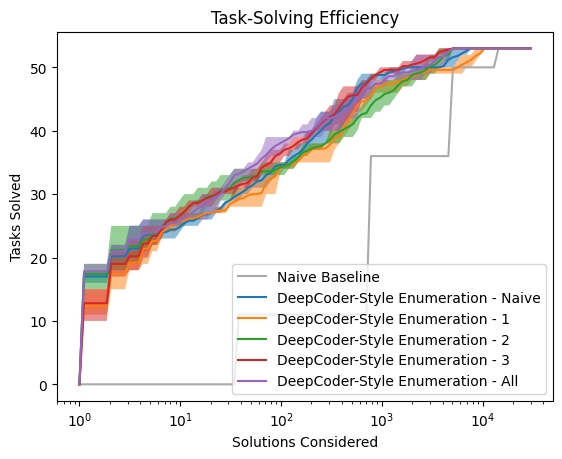

In [8]:
scores = plot_task_solving_efficiency(results)


In [9]:
# DeepCoder enumeration with NN ensemble

for p1 in ["Score-Mean", "Score-Min", "Score-Max", "Mean-Score", "Min-Score", "Max-Score"]:

    label = f"DeepCoder-Style Enumeration Ensemble - {p1}"

    metadata[label] = []

    for i, s in enumerate(SEEDS):
        metadata[label].append({
            "seed": s,
            "prediction_nns": [
                metadata["DeepCoder-Style Enumeration - 1"][i]["prediction_nns"][0],
                metadata["DeepCoder-Style Enumeration - 2"][i]["prediction_nns"][0],
                metadata["DeepCoder-Style Enumeration - 3"][i]["prediction_nns"][0],
            ],
            "predictor_reduction": p1,
            "demonstration_reduction": "Mean",
        })


In [10]:
results = try_all_tasks(metadata, results)



Now using: DeepCoder-Style Enumeration Ensemble - Score-Mean

Now solving 1cf80156...


0it [00:00, ?it/s]


Program found: `GridHypothesis; Crop(x)()` correctly solved all demonstrations (1th attempt)
Correct: Found solution program 1 correctly solved all queries.


0it [00:00, ?it/s]


Program found: `GridHypothesis; Crop(x)()` correctly solved all demonstrations (1th attempt)
Correct: Found solution program 1 correctly solved all queries.


0it [00:00, ?it/s]


... (3,224 outputs left out)

151it [00:00, 5462.28it/s]


Program found: `ColourHypothesis; ArgMax(Crop(x)(), ObjectGetPixelCount(x)())()` correctly solved all demonstrations (152th attempt)
Correct: Found solution program 1 correctly solved all queries.


123it [00:00, 6775.13it/s]

Program found: `TwoConnectedHypothesis; ArgMax(Crop(x)(), ObjectGetPixelCount(x)())()` correctly solved all demonstrations (124th attempt)
Correct: Found solution program 1 correctly solved all queries.


Scores (Average Area Under the Curve):
	                                   Naive Baseline: 0.359
	              DeepCoder-Style Enumeration - Naive: 0.708
	                  DeepCoder-Style Enumeration - 1: 0.680
	                  DeepCoder-Style Enumeration - 2: 0.704
	                  DeepCoder-Style Enumeration - 3: 0.717
	                DeepCoder-Style Enumeration - All: 0.725
	DeepCoder-Style Enumeration Ensemble - Score-Mean: 0.742
	 DeepCoder-Style Enumeration Ensemble - Score-Min: 0.708
	 DeepCoder-Style Enumeration Ensemble - Score-Max: 0.743
	DeepCoder-Style Enumeration Ensemble - Mean-Score: 0.757
	 DeepCoder-Style Enumeration Ensemble - Min-Score: 0.689
	 DeepCoder-Style Enumeration Ensemble - Max-Score: 0.772



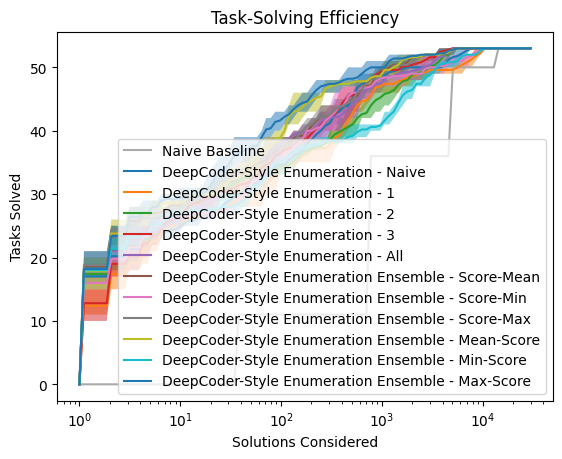

In [11]:
scores = plot_task_solving_efficiency(results)


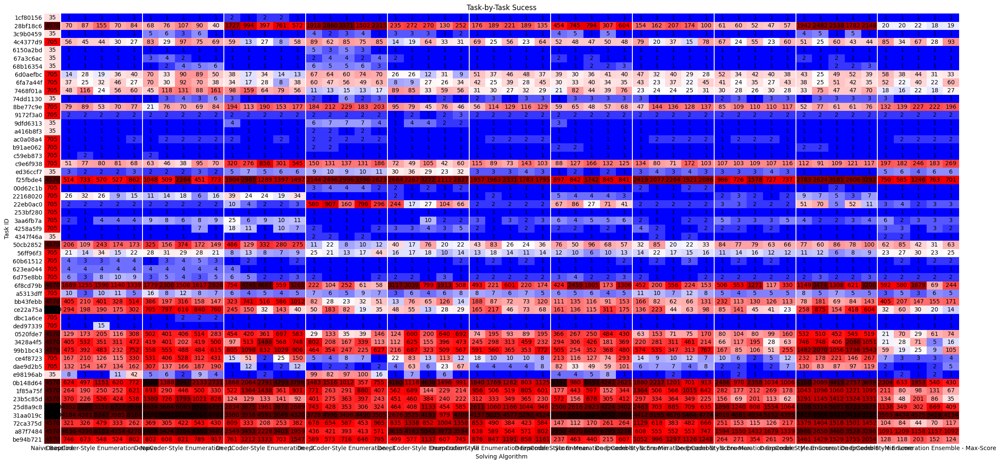

In [12]:
plot_task_by_task_results(results)


### New Idea: VSA-Guided Synthesis

In [13]:
# Hybrid enumeration with 1 NN

for p1 in ["Naive", "1", "2", "3", "All"]:
    for p2 in ["Random", "Typetagged Learned SSP", "Engineered SSP"]:

        label = f"Hybrid-VSA Enumeration - {p1} - {p2}"
    
        metadata[label] = []
    
        for i, s in enumerate(SEEDS):
            
            if (p2 == "Random"):
                embeddings = random_embeddings(
                    embedding_dim=PROGRAM_REPRESENTATION_DIMENSIONS,
                    seed=s,
                )
            elif (p2 == "Learned"):
                embeddings = learned_embeddings(
                    source_embeddings=metadata["DeepCoder-Style Enumeration - All"][i]["prediction_nns"][0].nn[-2].weight.detach().numpy(),
                    normalized=True,
                    type_tags=False,
                    type_tags_mode=None,
                    seed=s,
                )
            elif (p2 == "Typetagged Learned"):
                embeddings = learned_embeddings(
                    source_embeddings=metadata["DeepCoder-Style Enumeration - All"][i]["prediction_nns"][0].nn[-2].weight.detach().numpy(),
                    normalized=True,
                    type_tags=True,
                    type_tags_mode="Basic",
                    seed=s,
                )
            elif (p2 == "Correlated Typetagged Learned"):
                embeddings = learned_embeddings(
                    source_embeddings=metadata["DeepCoder-Style Enumeration - All"][i]["prediction_nns"][0].nn[-2].weight.detach().numpy(),
                    normalized=True,
                    type_tags=True,
                    type_tags_mode="Correlated",
                    seed=s,
                )
            elif (p2 == "Learned SSP"):
                embeddings = ssp_embeddings(
                    embedding_dim=PROGRAM_REPRESENTATION_DIMENSIONS,
                    source_embeddings=metadata["DeepCoder-Style Enumeration - All"][i]["prediction_nns"][0].nn[-2].weight.detach().numpy(),
                    ssp_latent_dim=2,
                    ssp_length_scale=0.2,
                    type_tags=False,
                    type_tags_mode=None,
                    seed=s,
                )
            elif (p2 == "Typetagged Learned SSP"):
                embeddings = ssp_embeddings(
                    embedding_dim=PROGRAM_REPRESENTATION_DIMENSIONS,
                    source_embeddings=metadata["DeepCoder-Style Enumeration - All"][i]["prediction_nns"][0].nn[-2].weight.detach().numpy(),
                    ssp_latent_dim=2,
                    ssp_length_scale=0.2,
                    type_tags=True,
                    type_tags_mode="Basic",
                    seed=s,
                )
            elif (p2 == "Correlated Typetagged Learned SSP"):
                embeddings = ssp_embeddings(
                    embedding_dim=PROGRAM_REPRESENTATION_DIMENSIONS,
                    source_embeddings=metadata["DeepCoder-Style Enumeration - All"][i]["prediction_nns"][0].nn[-2].weight.detach().numpy(),
                    ssp_latent_dim=2,
                    ssp_length_scale=0.2,
                    type_tags=True,
                    type_tags_mode="Correlated",
                    seed=s,
                )
            elif (p2 == "Engineered SSP"):
                embeddings = ssp_embeddings(
                    embedding_dim=PROGRAM_REPRESENTATION_DIMENSIONS,
                    source_embeddings=np.load("engineered_embeddings_source.npy"),
                    ssp_latent_dim=2,
                    ssp_length_scale=0.2,
                    type_tags=False,
                    type_tags_mode=None,
                    seed=s,
                )
            elif (p2 == "Typetagged Engineered SSP"):
                embeddings = ssp_embeddings(
                    embedding_dim=PROGRAM_REPRESENTATION_DIMENSIONS,
                    source_embeddings=np.load("engineered_embeddings_source.npy"),
                    ssp_latent_dim=2,
                    ssp_length_scale=0.2,
                    type_tags=True,
                    type_tags_mode="Basic",
                    seed=s,
                )
            elif (p2 == "Correlated Typetagged Engineered SSP"):
                embeddings = ssp_embeddings(
                    embedding_dim=PROGRAM_REPRESENTATION_DIMENSIONS,
                    source_embeddings=np.load("engineered_embeddings_source.npy"),
                    ssp_latent_dim=2,
                    ssp_length_scale=0.2,
                    type_tags=True,
                    type_tags_mode="Correlated",
                    seed=s,
                )
            else:
                assert False

            metadata[label].append({
                "seed": s,
                "prediction_nns": metadata[f"DeepCoder-Style Enumeration - {p1}"][i]["prediction_nns"],
                "predictor_reduction": "Mean-Project-Score",
                "demonstration_reduction": "Mean",
                "embeddings": embeddings,
                "projection_mode": "Matrix",
                "score_mode": "Softplus",
                "subtract_mode": "Conditioned",
                "beam_size": N_PRIMITIVES,
                "max_depth": 2,
            })


In [14]:
# Hybrid enumeration with NN ensemble

for p1 in ["Project-Score-Mean", "Project-Score-Min", "Project-Score-Max", "Project-Mean-Score", "Mean-Project-Score", "Min-Project-Score", "Max-Project-Score"]:
    for p2 in ["Random", "Typetagged Learned SSP", "Engineered SSP"]:

        label = f"Hybrid-VSA Enumeration Ensemble - {p1} - {p2}"

        metadata[label] = []
    
        for i, s in enumerate(SEEDS):
    
            if (p2 == "Random"):
                embeddings = random_embeddings(
                    embedding_dim=PROGRAM_REPRESENTATION_DIMENSIONS,
                    seed=s,
                )
            elif (p2 == "Learned"):
                embeddings = learned_embeddings(
                    source_embeddings=metadata["DeepCoder-Style Enumeration - All"][i]["prediction_nns"][0].nn[-2].weight.detach().numpy(),
                    normalized=True,
                    type_tags=False,
                    type_tags_mode=None,
                    seed=s,
                )
            elif (p2 == "Typetagged Learned"):
                embeddings = learned_embeddings(
                    source_embeddings=metadata["DeepCoder-Style Enumeration - All"][i]["prediction_nns"][0].nn[-2].weight.detach().numpy(),
                    normalized=True,
                    type_tags=True,
                    type_tags_mode="Basic",
                    seed=s,
                )
            elif (p2 == "Correlated Typetagged Learned"):
                embeddings = learned_embeddings(
                    source_embeddings=metadata["DeepCoder-Style Enumeration - All"][i]["prediction_nns"][0].nn[-2].weight.detach().numpy(),
                    normalized=True,
                    type_tags=True,
                    type_tags_mode="Correlated",
                    seed=s,
                )
            elif (p2 == "Learned SSP"):
                embeddings = ssp_embeddings(
                    embedding_dim=PROGRAM_REPRESENTATION_DIMENSIONS,
                    source_embeddings=metadata["DeepCoder-Style Enumeration - All"][i]["prediction_nns"][0].nn[-2].weight.detach().numpy(),
                    ssp_latent_dim=2,
                    ssp_length_scale=0.2,
                    type_tags=False,
                    type_tags_mode=None,
                    seed=s,
                )
            elif (p2 == "Typetagged Learned SSP"):
                embeddings = ssp_embeddings(
                    embedding_dim=PROGRAM_REPRESENTATION_DIMENSIONS,
                    source_embeddings=metadata["DeepCoder-Style Enumeration - All"][i]["prediction_nns"][0].nn[-2].weight.detach().numpy(),
                    ssp_latent_dim=2,
                    ssp_length_scale=0.2,
                    type_tags=True,
                    type_tags_mode="Basic",
                    seed=s,
                )
            elif (p2 == "Correlated Typetagged Learned SSP"):
                embeddings = ssp_embeddings(
                    embedding_dim=PROGRAM_REPRESENTATION_DIMENSIONS,
                    source_embeddings=metadata["DeepCoder-Style Enumeration - All"][i]["prediction_nns"][0].nn[-2].weight.detach().numpy(),
                    ssp_latent_dim=2,
                    ssp_length_scale=0.2,
                    type_tags=True,
                    type_tags_mode="Correlated",
                    seed=s,
                )
            elif (p2 == "Engineered SSP"):
                embeddings = ssp_embeddings(
                    embedding_dim=PROGRAM_REPRESENTATION_DIMENSIONS,
                    source_embeddings=np.load("engineered_embeddings_source.npy"),
                    ssp_latent_dim=2,
                    ssp_length_scale=0.2,
                    type_tags=False,
                    type_tags_mode=None,
                    seed=s,
                )
            elif (p2 == "Typetagged Engineered SSP"):
                embeddings = ssp_embeddings(
                    embedding_dim=PROGRAM_REPRESENTATION_DIMENSIONS,
                    source_embeddings=np.load("engineered_embeddings_source.npy"),
                    ssp_latent_dim=2,
                    ssp_length_scale=0.2,
                    type_tags=True,
                    type_tags_mode="Basic",
                    seed=s,
                )
            elif (p2 == "Correlated Typetagged Engineered SSP"):
                embeddings = ssp_embeddings(
                    embedding_dim=PROGRAM_REPRESENTATION_DIMENSIONS,
                    source_embeddings=np.load("engineered_embeddings_source.npy"),
                    ssp_latent_dim=2,
                    ssp_length_scale=0.2,
                    type_tags=True,
                    type_tags_mode="Correlated",
                    seed=s,
                )
            else:
                assert False
    
            metadata[label].append({
                "seed": s,
                "prediction_nns": [
                    metadata["DeepCoder-Style Enumeration - 1"][i]["prediction_nns"][0],
                    metadata["DeepCoder-Style Enumeration - 2"][i]["prediction_nns"][0],
                    metadata["DeepCoder-Style Enumeration - 3"][i]["prediction_nns"][0],
                ],
                "predictor_reduction": p1,
                "demonstration_reduction": "Mean",
                "embeddings": embeddings,
                "projection_mode": "Matrix",
                "score_mode": "Softplus",
                "subtract_mode": "Conditioned",
                "beam_size": N_PRIMITIVES,
                "max_depth": 2,
            })


In [15]:
results = try_all_tasks(metadata, results)



Now using: Hybrid-VSA Enumeration - Naive - Random

Now solving 1cf80156...


0it [00:00, ?it/s]


Program found: `GridHypothesis; Crop(x)()` correctly solved all demonstrations (1th attempt)
Correct: Found solution program 1 correctly solved all queries.


0it [00:00, ?it/s]


Program found: `GridHypothesis; Crop(x)()` correctly solved all demonstrations (1th attempt)
Correct: Found solution program 1 correctly solved all queries.


0it [00:00, ?it/s]


... (19,136 outputs left out)

88it [00:00, 4762.93it/s]


Program found: `ColourHypothesis; ArgMax(Crop(x)(), ObjectGetPixelCount(x)())()` correctly solved all demonstrations (89th attempt)
Correct: Found solution program 1 correctly solved all queries.


83it [00:00, 5033.07it/s]

Program found: `TwoConnectedHypothesis; Crop(ArgMax(x, ObjectGetPixelCount(x)())())()` correctly solved all demonstrations (84th attempt)
Correct: Found solution program 1 correctly solved all queries.


Scores (Average Area Under the Curve):
	                                                               Naive Baseline: 0.359
	                                          DeepCoder-Style Enumeration - Naive: 0.708
	                                              DeepCoder-Style Enumeration - 1: 0.680
	                                              DeepCoder-Style Enumeration - 2: 0.704
	                                              DeepCoder-Style Enumeration - 3: 0.717
	                                            DeepCoder-Style Enumeration - All: 0.725
	                            DeepCoder-Style Enumeration Ensemble - Score-Mean: 0.742
	                             DeepCoder-Style Enumeration Ensemble - Score-Min: 0.708
	                             DeepCoder-Style Enumeration Ensemble - Score-Max: 0.743
	                            DeepCoder-Style Enumeration Ensemble - Mean-Score: 0.757
	                             DeepCoder-Style Enumeration Ensemble - Min-Score: 0.689
	              

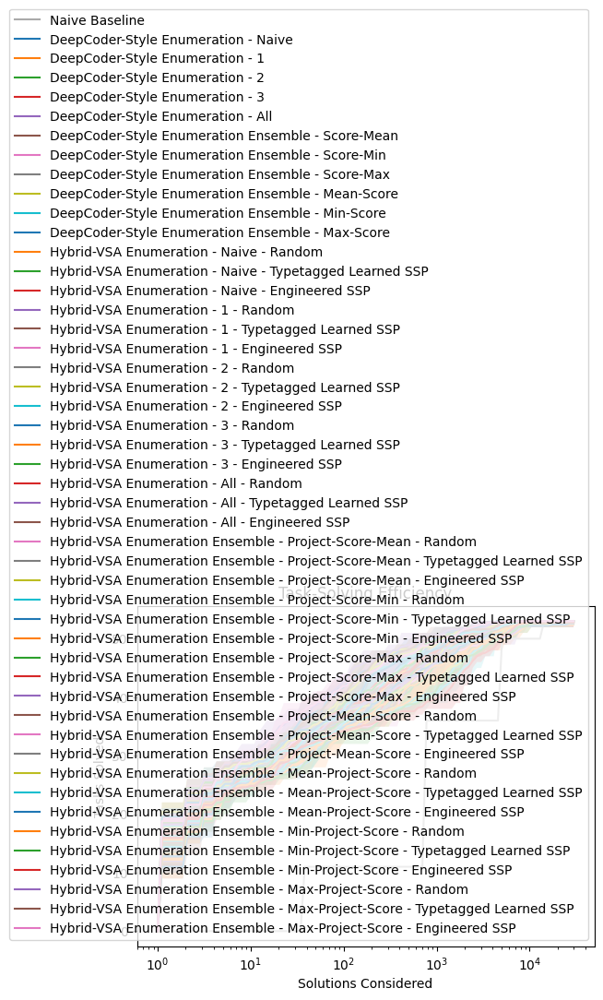

In [16]:
scores = plot_task_solving_efficiency(results)


In [17]:
# GOAT-DeepCoder evolution with 1 NN

for p1 in ["Naive", "1", "2", "3", "All"]:

    label = f"DeepCoder-Style GOAT Evolution - {p1}"

    metadata[label] = []

    for i, s in enumerate(SEEDS):
        embeddings = random_embeddings(
            embedding_dim=PROGRAM_REPRESENTATION_DIMENSIONS,
            seed=s,
        )

        metadata[label].append({
            "seed": s,
            "prediction_nns": metadata[f"DeepCoder-Style Enumeration - {p1}"][i]["prediction_nns"],
            "predictor_reduction": "Mean-Score",
            "demonstration_reduction": "Mean",
            "embeddings": embeddings,
            "projection_mode": "Matrix",
            "score_mode": "Softplus",
            "subtract_mode": "Conditioned",
            "beam_size": N_PRIMITIVES,
            "max_depth": 2,
            "update_weight": 0,
            "encoding_reduction": "Mean",
            "intermediate_reduction": "Rectify-Mean",
            "formula": "Default",
            "fix_deep": True,
            "ranker": "DeepCoder",
            "encode_fcns": [eval(f"encode_grid_{p1.lower()}")],
        })


In [18]:
results = try_all_tasks(metadata, results)



Now using: DeepCoder-Style GOAT Evolution - Naive

Now solving 1cf80156...
Program found: "GridHypothesis; Crop(x)()" correctly solved all demonstrations (1th attempt)
Correct: Found solution program 1 correctly solved all queries.
Program found: "GridHypothesis; Crop(x)()" correctly solved all demonstrations (1th attempt)
Correct: Found solution program 1 correctly solved all queries.
Program found: "GridHypothesis; Crop(x)()" correctly solved all demonstrations (1th attempt)
Correct: Found solution program 1 correctly solved all queries.
Program found: "GridHypothesis; Crop(x)()" correctly solved all demonstrations (1th attempt)
Correct: Found solution program 1 correctly solved all queries.
Program found: "GridHypothesis; Crop(x)()" correctly solved all demonstrations (1th attempt)
Correct: Found solution program 1 correctly solved all queries.

Now solving 28bf18c6...
Program found: "GridHypothesis; HStack(Crop(x)(), Crop(x)())()" correctly solved all demonstrations (12th attempt)

36it [00:00, 9830.40it/s]


Program found: `GridHypothesis; VStack(VFlip(x)(), x)()` correctly solved all demonstrations (37th attempt)
Correct: Found solution program 1 correctly solved all queries.
Program found: "GridHypothesis; VStack(VFlip(x)(), x)()" correctly solved all demonstrations (6th attempt)
Correct: Found solution program 1 correctly solved all queries.
Program found: "GridHypothesis; VStack(VFlip(x)(), x)()" correctly solved all demonstrations (11th attempt)
Correct: Found solution program 1 correctly solved all queries.

Now solving 6150a2bd...
Program found: "GridHypothesis; Rot180(x)()" correctly solved all demonstrations (1th attempt)
Correct: Found solution program 1 correctly solved all queries.
Program found: "GridHypothesis; Rot180(x)()" correctly solved all demonstrations (1th attempt)
Correct: Found solution program 1 correctly solved all queries.
Program found: "GridHypothesis; Rot180(x)()" correctly solved all demonstrations (1th attempt)
Correct: Found solution program 1 correctly sol

59it [00:00, 10750.89it/s]


Program found: `GridHypothesis; HStack(x, HFlip(x)())()` correctly solved all demonstrations (60th attempt)
Correct: Found solution program 1 correctly solved all queries.
Program found: "GridHypothesis; HStack(x, HFlip(x)())()" correctly solved all demonstrations (22th attempt)
Correct: Found solution program 1 correctly solved all queries.


68it [00:00, 10658.17it/s]


... (573 outputs left out)

521it [00:00, 3564.64it/s]


Program found: `TwoConnectedHypothesis; ArgMax(Crop(x)(), ObjectGetPixelCount(x)())()` correctly solved all demonstrations (522th attempt)
Correct: Found solution program 1 correctly solved all queries.


645it [00:00, 3527.44it/s]

Program found: `TwoConnectedHypothesis; ArgMax(Crop(x)(), ObjectGetPixelCount(x)())()` correctly solved all demonstrations (646th attempt)
Correct: Found solution program 1 correctly solved all queries.


Scores (Average Area Under the Curve):
	                                                               Naive Baseline: 0.359
	                                          DeepCoder-Style Enumeration - Naive: 0.708
	                                              DeepCoder-Style Enumeration - 1: 0.680
	                                              DeepCoder-Style Enumeration - 2: 0.704
	                                              DeepCoder-Style Enumeration - 3: 0.717
	                                            DeepCoder-Style Enumeration - All: 0.725
	                            DeepCoder-Style Enumeration Ensemble - Score-Mean: 0.742
	                             DeepCoder-Style Enumeration Ensemble - Score-Min: 0.708
	                             DeepCoder-Style Enumeration Ensemble - Score-Max: 0.743
	                            DeepCoder-Style Enumeration Ensemble - Mean-Score: 0.757
	                             DeepCoder-Style Enumeration Ensemble - Min-Score: 0.689
	              

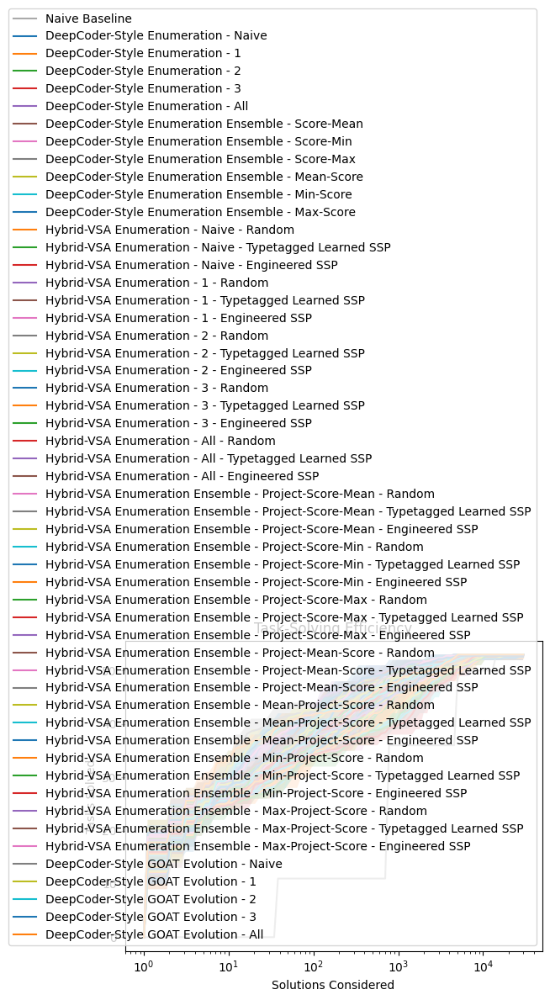

In [19]:
scores = plot_task_solving_efficiency(results)


In [20]:
# GOAT-Hybrid evolution with 1 NN

for p1 in ["Naive", "1", "2", "3", "All"]:
    for p2 in ["Random", "Typetagged Learned SSP", "Engineered SSP"]:

        label = f"Hybrid GOAT Evolution - {p1} - {p2}"
    
        metadata[label] = []
    
        for i, s in enumerate(SEEDS):

            if (p2 == "Random"):
                embeddings = random_embeddings(
                    embedding_dim=PROGRAM_REPRESENTATION_DIMENSIONS,
                    seed=s,
                )
            elif (p2 == "Learned"):
                embeddings = learned_embeddings(
                    source_embeddings=metadata["DeepCoder-Style Enumeration - All"][i]["prediction_nns"][0].nn[-2].weight.detach().numpy(),
                    normalized=True,
                    type_tags=False,
                    type_tags_mode=None,
                    seed=s,
                )
            elif (p2 == "Typetagged Learned"):
                embeddings = learned_embeddings(
                    source_embeddings=metadata["DeepCoder-Style Enumeration - All"][i]["prediction_nns"][0].nn[-2].weight.detach().numpy(),
                    normalized=True,
                    type_tags=True,
                    type_tags_mode="Basic",
                    seed=s,
                )
            elif (p2 == "Correlated Typetagged Learned"):
                embeddings = learned_embeddings(
                    source_embeddings=metadata["DeepCoder-Style Enumeration - All"][i]["prediction_nns"][0].nn[-2].weight.detach().numpy(),
                    normalized=True,
                    type_tags=True,
                    type_tags_mode="Correlated",
                    seed=s,
                )
            elif (p2 == "Learned SSP"):
                embeddings = ssp_embeddings(
                    embedding_dim=PROGRAM_REPRESENTATION_DIMENSIONS,
                    source_embeddings=metadata["DeepCoder-Style Enumeration - All"][i]["prediction_nns"][0].nn[-2].weight.detach().numpy(),
                    ssp_latent_dim=2,
                    ssp_length_scale=0.2,
                    type_tags=False,
                    type_tags_mode=None,
                    seed=s,
                )
            elif (p2 == "Typetagged Learned SSP"):
                embeddings = ssp_embeddings(
                    embedding_dim=PROGRAM_REPRESENTATION_DIMENSIONS,
                    source_embeddings=metadata["DeepCoder-Style Enumeration - All"][i]["prediction_nns"][0].nn[-2].weight.detach().numpy(),
                    ssp_latent_dim=2,
                    ssp_length_scale=0.2,
                    type_tags=True,
                    type_tags_mode="Basic",
                    seed=s,
                )
            elif (p2 == "Correlated Typetagged Learned SSP"):
                embeddings = ssp_embeddings(
                    embedding_dim=PROGRAM_REPRESENTATION_DIMENSIONS,
                    source_embeddings=metadata["DeepCoder-Style Enumeration - All"][i]["prediction_nns"][0].nn[-2].weight.detach().numpy(),
                    ssp_latent_dim=2,
                    ssp_length_scale=0.2,
                    type_tags=True,
                    type_tags_mode="Correlated",
                    seed=s,
                )
            elif (p2 == "Engineered SSP"):
                embeddings = ssp_embeddings(
                    embedding_dim=PROGRAM_REPRESENTATION_DIMENSIONS,
                    source_embeddings=np.load("engineered_embeddings_source.npy"),
                    ssp_latent_dim=2,
                    ssp_length_scale=0.2,
                    type_tags=False,
                    type_tags_mode=None,
                    seed=s,
                )
            elif (p2 == "Typetagged Engineered SSP"):
                embeddings = ssp_embeddings(
                    embedding_dim=PROGRAM_REPRESENTATION_DIMENSIONS,
                    source_embeddings=np.load("engineered_embeddings_source.npy"),
                    ssp_latent_dim=2,
                    ssp_length_scale=0.2,
                    type_tags=True,
                    type_tags_mode="Basic",
                    seed=s,
                )
            elif (p2 == "Correlated Typetagged Engineered SSP"):
                embeddings = ssp_embeddings(
                    embedding_dim=PROGRAM_REPRESENTATION_DIMENSIONS,
                    source_embeddings=np.load("engineered_embeddings_source.npy"),
                    ssp_latent_dim=2,
                    ssp_length_scale=0.2,
                    type_tags=True,
                    type_tags_mode="Correlated",
                    seed=s,
                )
            else:
                assert False
    
            metadata[label].append({
                "seed": s,
                "prediction_nns": metadata[f"DeepCoder-Style Enumeration - {p1}"][i]["prediction_nns"],
                "predictor_reduction": "Mean-Project-Score",
                "demonstration_reduction": "Mean",
                "embeddings": embeddings,
                "projection_mode": "Matrix",
                "score_mode": "Softplus",
                "subtract_mode": "Conditioned",
                "beam_size": N_PRIMITIVES,
                "max_depth": 2,
                "update_weight": 0,
                "encoding_reduction": "Mean",
                "intermediate_reduction": "Rectify-Mean",
                "formula": "Default",
                "fix_deep": True,
                "ranker": "Hybrid",
                "encode_fcns": [eval(f"encode_grid_{p1.lower()}")],
            })


In [21]:
results = try_all_tasks(metadata, results)



Now using: Hybrid GOAT Evolution - Naive - Random

Now solving 1cf80156...
Program found: "GridHypothesis; Crop(x)()" correctly solved all demonstrations (1th attempt)
Correct: Found solution program 1 correctly solved all queries.
Program found: "GridHypothesis; Crop(x)()" correctly solved all demonstrations (1th attempt)
Correct: Found solution program 1 correctly solved all queries.
Program found: "GridHypothesis; Crop(x)()" correctly solved all demonstrations (1th attempt)
Correct: Found solution program 1 correctly solved all queries.
Program found: "GridHypothesis; Crop(x)()" correctly solved all demonstrations (1th attempt)
Correct: Found solution program 1 correctly solved all queries.
Program found: "GridHypothesis; Crop(x)()" correctly solved all demonstrations (1th attempt)
Correct: Found solution program 1 correctly solved all queries.

Now solving 28bf18c6...
Program found: "GridHypothesis; HStack(Crop(x)(), Crop(x)())()" correctly solved all demonstrations (5th attempt)


28it [00:00, 8526.25it/s]


Program found: `GridHypothesis; VStack(VFlip(x)(), x)()` correctly solved all demonstrations (29th attempt)
Correct: Found solution program 1 correctly solved all queries.
Program found: "GridHypothesis; VStack(VFlip(x)(), x)()" correctly solved all demonstrations (6th attempt)
Correct: Found solution program 1 correctly solved all queries.


19it [00:00, 10064.63it/s]


Program found: `GridHypothesis; VStack(VFlip(x)(), x)()` correctly solved all demonstrations (20th attempt)
Correct: Found solution program 1 correctly solved all queries.
Program found: "GridHypothesis; VStack(VFlip(x)(), x)()" correctly solved all demonstrations (4th attempt)
Correct: Found solution program 1 correctly solved all queries.
Program found: "GridHypothesis; VStack(VFlip(x)(), x)()" correctly solved all demonstrations (7th attempt)
Correct: Found solution program 1 correctly solved all queries.

Now solving 6150a2bd...
Program found: "GridHypothesis; Rot180(x)()" correctly solved all demonstrations (1th attempt)
Correct: Found solution program 1 correctly solved all queries.
Program found: "GridHypothesis; Rot180(x)()" correctly solved all demonstrations (1th attempt)
Correct: Found solution program 1 correctly solved all queries.
Program found: "GridHypothesis; Rot180(x)()" correctly solved all demonstrations (1th attempt)
Correct: Found solution program 1 correctly solv

334it [00:00, 2872.23it/s]


... (1,663 outputs left out)

374it [00:00, 6375.95it/s]


Program found: `ColourHypothesis; Crop(ArgMax(x, ObjectGetPixelCount(x)())())()` correctly solved all demonstrations (375th attempt)
Correct: Found solution program 1 correctly solved all queries.


257it [00:00, 1790.18it/s]

Program found: `TwoConnectedHypothesis; Crop(ArgMax(x, ObjectGetPixelCount(x)())())()` correctly solved all demonstrations (258th attempt)
Correct: Found solution program 1 correctly solved all queries.


Scores (Average Area Under the Curve):
	                                                               Naive Baseline: 0.359
	                                          DeepCoder-Style Enumeration - Naive: 0.708
	                                              DeepCoder-Style Enumeration - 1: 0.680
	                                              DeepCoder-Style Enumeration - 2: 0.704
	                                              DeepCoder-Style Enumeration - 3: 0.717
	                                            DeepCoder-Style Enumeration - All: 0.725
	                            DeepCoder-Style Enumeration Ensemble - Score-Mean: 0.742
	                             DeepCoder-Style Enumeration Ensemble - Score-Min: 0.708
	                             DeepCoder-Style Enumeration Ensemble - Score-Max: 0.743
	                            DeepCoder-Style Enumeration Ensemble - Mean-Score: 0.757
	                             DeepCoder-Style Enumeration Ensemble - Min-Score: 0.689
	              

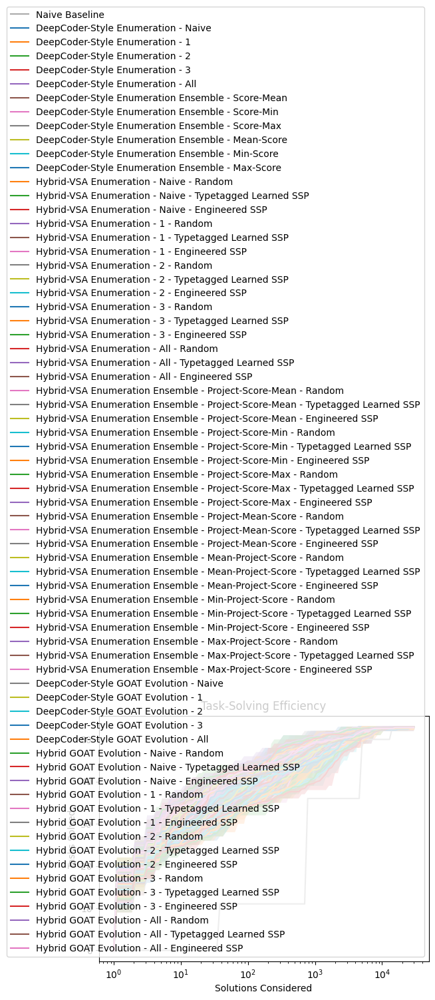

In [22]:
scores = plot_task_solving_efficiency(results)


In [23]:
# GOAT-DeepCoder evolution with NN ensemble

for p1 in ["Score-Mean", "Score-Min", "Score-Max", "Mean-Score", "Min-Score", "Max-Score"]:

    label = f"DeepCoder-Style GOAT Evolution Ensemble - {p1}"

    metadata[label] = []

    for i, s in enumerate(SEEDS):
        embeddings = random_embeddings(
            embedding_dim=PROGRAM_REPRESENTATION_DIMENSIONS,
            seed=s,
        )

        metadata[label].append({
            "seed": s,
            "prediction_nns": [
                metadata["DeepCoder-Style Enumeration - 1"][i]["prediction_nns"][0],
                metadata["DeepCoder-Style Enumeration - 2"][i]["prediction_nns"][0],
                metadata["DeepCoder-Style Enumeration - 3"][i]["prediction_nns"][0],
            ],
            "predictor_reduction": p1,
            "demonstration_reduction": "Mean",
            "embeddings": embeddings,
            "projection_mode": "Matrix",
            "score_mode": "Softplus",
            "subtract_mode": "Conditioned",
            "beam_size": N_PRIMITIVES,
            "max_depth": 2,
            "update_weight": 0,
            "encoding_reduction": "Max",
            "intermediate_reduction": "Rectify-Mean",
            "formula": "Default",
            "fix_deep": True,
            "ranker": "DeepCoder",
            "encode_fcns": [eval("encode_grid_1"), eval("encode_grid_2"), eval("encode_grid_3")],
        })


In [24]:
results = try_all_tasks(metadata, results)



Now using: DeepCoder-Style GOAT Evolution Ensemble - Score-Mean

Now solving 1cf80156...
Program found: "GridHypothesis; Crop(x)()" correctly solved all demonstrations (1th attempt)
Correct: Found solution program 1 correctly solved all queries.
Program found: "GridHypothesis; Crop(x)()" correctly solved all demonstrations (1th attempt)
Correct: Found solution program 1 correctly solved all queries.
Program found: "GridHypothesis; Crop(x)()" correctly solved all demonstrations (1th attempt)
Correct: Found solution program 1 correctly solved all queries.
Program found: "GridHypothesis; Crop(x)()" correctly solved all demonstrations (1th attempt)
Correct: Found solution program 1 correctly solved all queries.
Program found: "GridHypothesis; Crop(x)()" correctly solved all demonstrations (1th attempt)
Correct: Found solution program 1 correctly solved all queries.

Now solving 28bf18c6...
Program found: "GridHypothesis; HStack(Crop(x)(), Crop(x)())()" correctly solved all demonstrations 

0it [00:00, ?it/s]


Program found: `ColourHypothesis; Rectangify(x, ObjectGetColour(x)())()` correctly solved all demonstrations (1th attempt)
Correct: Found solution program 1 correctly solved all queries.
Program found: "ColourHypothesis; Rectangify(x, ObjectGetColour(x)())()" correctly solved all demonstrations (24th attempt)
Correct: Found solution program 1 correctly solved all queries.


2it [00:00, 971.35it/s]


Program found: `ColourHypothesis; Rectangify(x, ObjectGetColour(x)())()` correctly solved all demonstrations (3th attempt)
Correct: Found solution program 1 correctly solved all queries.
Program found: "ColourHypothesis; Rectangify(x, ObjectGetColour(x)())()" correctly solved all demonstrations (23th attempt)
Correct: Found solution program 1 correctly solved all queries.

Now solving 60b61512...
Program found: "TwoConnectedHypothesis; Rectangify(x, ColourConstant(Colour(ORANGE))())()" correctly solved all demonstrations (1th attempt)
Correct: Found solution program 1 correctly solved all queries.
Program found: "TwoConnectedHypothesis; Rectangify(x, ColourConstant(Colour(ORANGE))())()" correctly solved all demonstrations (2th attempt)
Correct: Found solution program 1 correctly solved all queries.
Program found: "TwoConnectedHypothesis; Rectangify(x, ColourConstant(Colour(ORANGE))())()" correctly solved all demonstrations (1th attempt)
Correct: Found solution program 1 correctly solve

150it [00:01, 83.07it/s]


... (509 outputs left out)

60it [00:00, 4317.50it/s]


Program found: `ColourHypothesis; ArgMax(Crop(x)(), ObjectGetPixelCount(x)())()` correctly solved all demonstrations (61th attempt)
Correct: Found solution program 1 correctly solved all queries.


20it [00:00, 5268.90it/s]

Program found: `TwoConnectedHypothesis; ArgMax(Crop(x)(), ObjectGetPixelCount(x)())()` correctly solved all demonstrations (21th attempt)
Correct: Found solution program 1 correctly solved all queries.


Scores (Average Area Under the Curve):
	                                                               Naive Baseline: 0.359
	                                          DeepCoder-Style Enumeration - Naive: 0.708
	                                              DeepCoder-Style Enumeration - 1: 0.680
	                                              DeepCoder-Style Enumeration - 2: 0.704
	                                              DeepCoder-Style Enumeration - 3: 0.717
	                                            DeepCoder-Style Enumeration - All: 0.725
	                            DeepCoder-Style Enumeration Ensemble - Score-Mean: 0.742
	                             DeepCoder-Style Enumeration Ensemble - Score-Min: 0.708
	                             DeepCoder-Style Enumeration Ensemble - Score-Max: 0.743
	                            DeepCoder-Style Enumeration Ensemble - Mean-Score: 0.757
	                             DeepCoder-Style Enumeration Ensemble - Min-Score: 0.689
	              

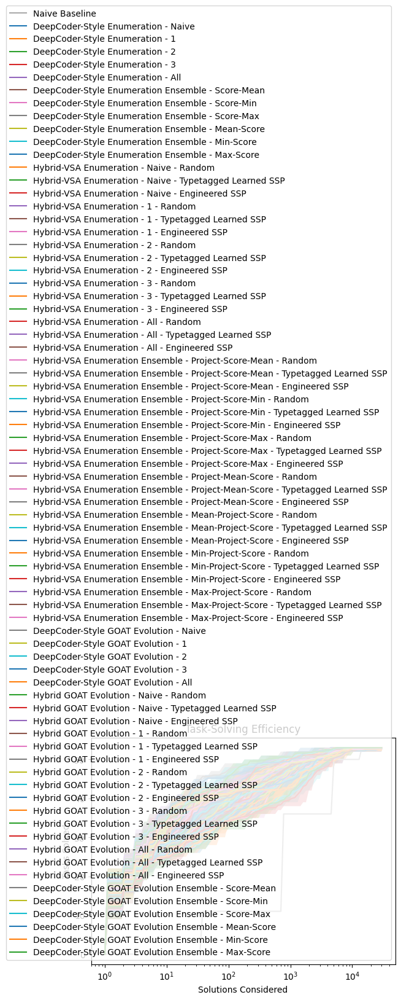

In [25]:
scores = plot_task_solving_efficiency(results)


In [26]:
# GOAT-Hybrid evolution with NN ensemble

for p1 in ["Project-Score-Mean", "Project-Score-Min", "Project-Score-Max", "Project-Mean-Score", "Mean-Project-Score", "Min-Project-Score", "Max-Project-Score"]:
    for p2 in ["Random", "Typetagged Learned SSP", "Engineered SSP"]:

        label = f"Hybrid GOAT Evolution Ensemble - {p1} - {p2}"

        metadata[label] = []

        for i, s in enumerate(SEEDS):

            if (p2 == "Random"):
                embeddings = random_embeddings(
                    embedding_dim=PROGRAM_REPRESENTATION_DIMENSIONS,
                    seed=s,
                )
            elif (p2 == "Learned"):
                embeddings = learned_embeddings(
                    source_embeddings=metadata["DeepCoder-Style Enumeration - All"][i]["prediction_nns"][0].nn[-2].weight.detach().numpy(),
                    normalized=True,
                    type_tags=False,
                    type_tags_mode=None,
                    seed=s,
                )
            elif (p2 == "Typetagged Learned"):
                embeddings = learned_embeddings(
                    source_embeddings=metadata["DeepCoder-Style Enumeration - All"][i]["prediction_nns"][0].nn[-2].weight.detach().numpy(),
                    normalized=True,
                    type_tags=True,
                    type_tags_mode="Basic",
                    seed=s,
                )
            elif (p2 == "Correlated Typetagged Learned"):
                embeddings = learned_embeddings(
                    source_embeddings=metadata["DeepCoder-Style Enumeration - All"][i]["prediction_nns"][0].nn[-2].weight.detach().numpy(),
                    normalized=True,
                    type_tags=True,
                    type_tags_mode="Correlated",
                    seed=s,
                )
            elif (p2 == "Learned SSP"):
                embeddings = ssp_embeddings(
                    embedding_dim=PROGRAM_REPRESENTATION_DIMENSIONS,
                    source_embeddings=metadata["DeepCoder-Style Enumeration - All"][i]["prediction_nns"][0].nn[-2].weight.detach().numpy(),
                    ssp_latent_dim=2,
                    ssp_length_scale=0.2,
                    type_tags=False,
                    type_tags_mode=None,
                    seed=s,
                )
            elif (p2 == "Typetagged Learned SSP"):
                embeddings = ssp_embeddings(
                    embedding_dim=PROGRAM_REPRESENTATION_DIMENSIONS,
                    source_embeddings=metadata["DeepCoder-Style Enumeration - All"][i]["prediction_nns"][0].nn[-2].weight.detach().numpy(),
                    ssp_latent_dim=2,
                    ssp_length_scale=0.2,
                    type_tags=True,
                    type_tags_mode="Basic",
                    seed=s,
                )
            elif (p2 == "Correlated Typetagged Learned SSP"):
                embeddings = ssp_embeddings(
                    embedding_dim=PROGRAM_REPRESENTATION_DIMENSIONS,
                    source_embeddings=metadata["DeepCoder-Style Enumeration - All"][i]["prediction_nns"][0].nn[-2].weight.detach().numpy(),
                    ssp_latent_dim=2,
                    ssp_length_scale=0.2,
                    type_tags=True,
                    type_tags_mode="Correlated",
                    seed=s,
                )
            elif (p2 == "Engineered SSP"):
                embeddings = ssp_embeddings(
                    embedding_dim=PROGRAM_REPRESENTATION_DIMENSIONS,
                    source_embeddings=np.load("engineered_embeddings_source.npy"),
                    ssp_latent_dim=2,
                    ssp_length_scale=0.2,
                    type_tags=False,
                    type_tags_mode=None,
                    seed=s,
                )
            elif (p2 == "Typetagged Engineered SSP"):
                embeddings = ssp_embeddings(
                    embedding_dim=PROGRAM_REPRESENTATION_DIMENSIONS,
                    source_embeddings=np.load("engineered_embeddings_source.npy"),
                    ssp_latent_dim=2,
                    ssp_length_scale=0.2,
                    type_tags=True,
                    type_tags_mode="Basic",
                    seed=s,
                )
            elif (p2 == "Correlated Typetagged Engineered SSP"):
                embeddings = ssp_embeddings(
                    embedding_dim=PROGRAM_REPRESENTATION_DIMENSIONS,
                    source_embeddings=np.load("engineered_embeddings_source.npy"),
                    ssp_latent_dim=2,
                    ssp_length_scale=0.2,
                    type_tags=True,
                    type_tags_mode="Correlated",
                    seed=s,
                )
            else:
                assert False

            metadata[label].append({
                "seed": s,
                "prediction_nns": [
                    metadata["DeepCoder-Style Enumeration - 1"][i]["prediction_nns"][0],
                    metadata["DeepCoder-Style Enumeration - 2"][i]["prediction_nns"][0],
                    metadata["DeepCoder-Style Enumeration - 3"][i]["prediction_nns"][0],
                ],
                "predictor_reduction": p1,
                "demonstration_reduction": "Mean",
                "embeddings": embeddings,
                "projection_mode": "Matrix",
                "score_mode": "Softplus",
                "subtract_mode": "Conditioned",
                "beam_size": N_PRIMITIVES,
                "max_depth": 2,
                "update_weight": 0,
                "encoding_reduction": "Max",
                "intermediate_reduction": "Rectify-Mean",
                "formula": "Default",
                "fix_deep": True,
                "ranker": "Hybrid",
                "encode_fcns": [eval("encode_grid_1"), eval("encode_grid_2"), eval("encode_grid_3")],
            })


In [27]:
results = try_all_tasks(metadata, results)



Now using: Hybrid GOAT Evolution Ensemble - Project-Score-Mean - Random

Now solving 1cf80156...
Program found: "GridHypothesis; Crop(x)()" correctly solved all demonstrations (1th attempt)
Correct: Found solution program 1 correctly solved all queries.
Program found: "GridHypothesis; Crop(x)()" correctly solved all demonstrations (1th attempt)
Correct: Found solution program 1 correctly solved all queries.
Program found: "GridHypothesis; Crop(x)()" correctly solved all demonstrations (1th attempt)
Correct: Found solution program 1 correctly solved all queries.
Program found: "GridHypothesis; Crop(x)()" correctly solved all demonstrations (1th attempt)
Correct: Found solution program 1 correctly solved all queries.
Program found: "GridHypothesis; Crop(x)()" correctly solved all demonstrations (1th attempt)
Correct: Found solution program 1 correctly solved all queries.

Now solving 28bf18c6...
Program found: "GridHypothesis; HStack(Crop(x)(), Crop(x)())()" correctly solved all demonst

0it [00:00, ?it/s]


Program found: `GridHypothesis; Scale(x, NumberConstant(Number(3))())()` correctly solved all demonstrations (1th attempt)
Correct: Found solution program 1 correctly solved all queries.

Now solving 9dfd6313...
Program found: "GridHypothesis; Transpose(x)()" correctly solved all demonstrations (1th attempt)
Correct: Found solution program 1 correctly solved all queries.
Program found: "GridHypothesis; Transpose(x)()" correctly solved all demonstrations (1th attempt)
Correct: Found solution program 1 correctly solved all queries.
Program found: "GridHypothesis; Transpose(x)()" correctly solved all demonstrations (1th attempt)
Correct: Found solution program 1 correctly solved all queries.
Program found: "GridHypothesis; Transpose(x)()" correctly solved all demonstrations (1th attempt)
Correct: Found solution program 1 correctly solved all queries.
Program found: "GridHypothesis; Transpose(x)()" correctly solved all demonstrations (1th attempt)
Correct: Found solution program 1 correctl

1it [00:00, 444.08it/s]


Program found: `ColourHypothesis; FillHoles(x, ColourConstant(Colour(BLUE))())()` correctly solved all demonstrations (2th attempt)
Correct: Found solution program 1 correctly solved all queries.
Program found: "ColourHypothesis; FillHoles(x, ColourConstant(Colour(BLUE))())()" correctly solved all demonstrations (15th attempt)
Correct: Found solution program 1 correctly solved all queries.
Program found: "ColourHypothesis; FillHoles(x, ColourConstant(Colour(BLUE))())()" correctly solved all demonstrations (40th attempt)
Correct: Found solution program 1 correctly solved all queries.
Program found: "ColourHypothesis; FillHoles(x, ColourConstant(Colour(BLUE))())()" correctly solved all demonstrations (15th attempt)
Correct: Found solution program 1 correctly solved all queries.


1it [00:00, 133.92it/s]


... (1,548 outputs left out)

7it [00:00, 1966.39it/s]


Program found: `ColourHypothesis; Filter(Crop(x)(), ObjectIsHSymmetrical(x)())()` correctly solved all demonstrations (8th attempt)
Correct: Found solution program 1 correctly solved all queries.

Now solving a87f7484...
Program found: "TwoConnectedHypothesis; ArgMax(Crop(x)(), ObjectGetPixelCount(x)())()" correctly solved all demonstrations (85th attempt)
Correct: Found solution program 1 correctly solved all queries.


5284it [00:02, 1957.41it/s]


Program found: `ColourHypothesis; ArgMax(Crop(x)(), ObjectGetPixelCount(x)())()` correctly solved all demonstrations (5285th attempt)
Correct: Found solution program 1 correctly solved all queries.
Program found: "TwoConnectedHypothesis; ArgMax(Crop(x)(), ObjectGetPixelCount(x)())()" correctly solved all demonstrations (62th attempt)
Correct: Found solution program 1 correctly solved all queries.
Program found: "TwoConnectedHypothesis; ArgMax(Crop(x)(), ObjectGetPixelCount(x)())()" correctly solved all demonstrations (63th attempt)
Correct: Found solution program 1 correctly solved all queries.
Program found: "TwoConnectedHypothesis; ArgMax(Crop(x)(), ObjectGetPixelCount(x)())()" correctly solved all demonstrations (38th attempt)
Correct: Found solution program 1 correctly solved all queries.

Now solving be94b721...
Program found: "OneConnectedHypothesis; ArgMax(Crop(x)(), ObjectGetPixelCount(x)())()" correctly solved all demonstrations (55th attempt)
Correct: Found solution program 1

Scores (Average Area Under the Curve):
	                                                               Naive Baseline: 0.359
	                                          DeepCoder-Style Enumeration - Naive: 0.708
	                                              DeepCoder-Style Enumeration - 1: 0.680
	                                              DeepCoder-Style Enumeration - 2: 0.704
	                                              DeepCoder-Style Enumeration - 3: 0.717
	                                            DeepCoder-Style Enumeration - All: 0.725
	                            DeepCoder-Style Enumeration Ensemble - Score-Mean: 0.742
	                             DeepCoder-Style Enumeration Ensemble - Score-Min: 0.708
	                             DeepCoder-Style Enumeration Ensemble - Score-Max: 0.743
	                            DeepCoder-Style Enumeration Ensemble - Mean-Score: 0.757
	                             DeepCoder-Style Enumeration Ensemble - Min-Score: 0.689
	              

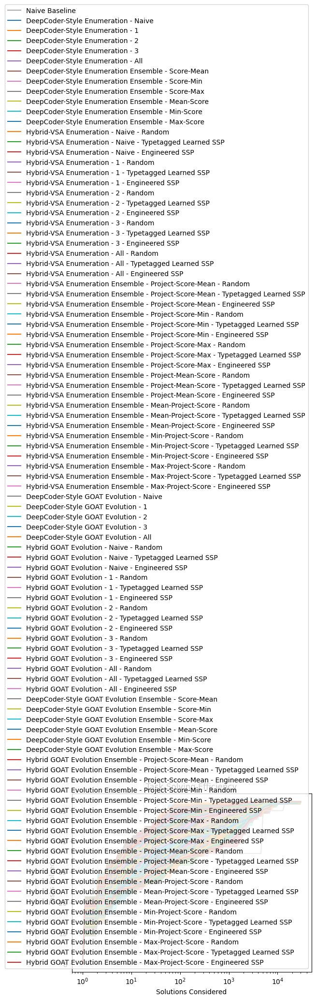

In [28]:
scores = plot_task_solving_efficiency(results)


In [29]:
np.savez("../results/New_10K_Data.npz", **results)
